# 🧠 Step 2.2 — Neural Baseline: BiLSTM Multi-task ABSA (Keras / TensorFlow)

**Mục tiêu:**
- Tokenize + build vocab từ `text_tokenized`
- Shared BiLSTM encoder + N classification heads (1 head / aspect)
- Class-weighted CrossEntropy (từ `class_weights.json`)
- Train với early-stopping theo Macro-F1 val
- (Optional) Load pretrained fastText Vietnamese embeddings
- So sánh với baseline TF-IDF

> ⚠️ Phiên bản này dùng **TensorFlow/Keras** thay cho PyTorch.
> Cài đặt: `pip install tensorflow`

In [37]:
import os, json, pathlib, random, warnings
# Giảm log của TF
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, Model, mixed_precision
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tqdm.auto import tqdm
from IPython.display import display
from sklearn.metrics import f1_score, classification_report

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# Ổn định trước: tắt mixed precision để tránh lỗi trace/mask với LSTM trên một số env
mixed_precision.set_global_policy('float32')
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    for gpu in gpus:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except Exception:
            pass

sns.set_theme(style='whitegrid')
print(f"✅ TensorFlow {tf.__version__} | policy={mixed_precision.global_policy().name} | GPUs: {gpus or 'none (CPU)'}")

✅ TensorFlow 2.16.1 | policy=float32 | GPUs: none (CPU)


## 1. Load processed data

In [38]:
processed_dir = pathlib.Path('../data/processed')
train = pd.read_parquet(processed_dir / 'train.parquet')
val   = pd.read_parquet(processed_dir / 'val.parquet')
test  = pd.read_parquet(processed_dir / 'test.parquet')

with open(processed_dir / 'metadata.json', encoding='utf-8') as fh:
    meta = json.load(fh)
with open(processed_dir / 'class_weights.json', encoding='utf-8') as fh:
    class_weights = json.load(fh)

aspect_cols = meta['aspect_cols']
text_col    = 'text_tokenized' if 'text_tokenized' in train.columns else 'text_clean'

NONE_LABEL = '__NONE__'
LABELS = [NONE_LABEL, 'positive', 'negative', 'neutral']
LABEL2ID = {l: i for i, l in enumerate(LABELS)}
ID2LABEL = {i: l for l, i in LABEL2ID.items()}
N_CLASSES = len(LABELS)

def to_label_ids(df):
    Y = df[aspect_cols].fillna(NONE_LABEL).astype(str)
    # map unknown → NONE
    Y = Y.map(lambda s: LABEL2ID.get(s, LABEL2ID[NONE_LABEL]))
    return Y.values.astype(np.int64)

Y_tr = to_label_ids(train)
Y_vl = to_label_ids(val)
Y_te = to_label_ids(test)

X_tr = train[text_col].fillna('').astype(str).tolist()
X_vl = val[text_col].fillna('').astype(str).tolist()
X_te = test[text_col].fillna('').astype(str).tolist()

print(f"Train/Val/Test: {len(X_tr)} / {len(X_vl)} / {len(X_te)}")
print(f"Aspects: {len(aspect_cols)}  |  Labels: {LABELS}")
print(f"Y_tr shape: {Y_tr.shape}")

Train/Val/Test: 2032 / 436 / 436
Aspects: 12  |  Labels: ['__NONE__', 'positive', 'negative', 'neutral']
Y_tr shape: (2032, 12)


## 2. Build Vocab + Encode

In [39]:
from collections import Counter

PAD, UNK = '<pad>', '<unk>'
MIN_FREQ = 2
MAX_VOCAB = 50_000
MAX_LEN = 150  # phù hợp CPU

def tokenize(s: str) -> list:
    return s.strip().split()

counter = Counter()
for s in X_tr:
    counter.update(tokenize(s))

itos = [PAD, UNK] + [w for w, c in counter.most_common(MAX_VOCAB) if c >= MIN_FREQ]
stoi = {w: i for i, w in enumerate(itos)}
PAD_ID = stoi[PAD]; UNK_ID = stoi[UNK]
print(f"📚 Vocab size: {len(itos):,}  (pad={PAD_ID}, unk={UNK_ID})")

def encode(s: str, max_len: int = MAX_LEN) -> list:
    ids = [stoi.get(w, UNK_ID) for w in tokenize(s)[:max_len]]
    return ids if ids else [UNK_ID]

lens = [len(tokenize(s)) for s in X_tr]
print(f"Length — median: {int(np.median(lens))}, p95: {int(np.percentile(lens, 95))}, max: {max(lens)}")

📚 Vocab size: 3,253  (pad=0, unk=1)
Length — median: 50, p95: 127, max: 199


## 3. Chuyển text → padded numpy arrays

In [40]:
def texts_to_padded(texts):
    seqs = [encode(s) for s in texts]
    return pad_sequences(seqs, maxlen=MAX_LEN, padding='post', truncating='post', value=PAD_ID)

Xtr = texts_to_padded(X_tr)
Xvl = texts_to_padded(X_vl)
Xte = texts_to_padded(X_te)

print(f"Xtr: {Xtr.shape} | Xvl: {Xvl.shape} | Xte: {Xte.shape}")

BATCH_SIZE = 64  # tăng từ 32 → 64

# ⚡ Tạo tf.data pipeline để tăng tốc I/O
def make_dataset(X, Y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X, Y))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(X), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE).cache().prefetch(tf.data.AUTOTUNE)
    return ds

ds_train = make_dataset(Xtr, Y_tr, shuffle=True)
ds_val   = make_dataset(Xvl, Y_vl)
ds_test  = make_dataset(Xte, Y_te)

Xtr: (2032, 150) | Xvl: (436, 150) | Xte: (436, 150)


## 4. (Optional) Load fastText VN embeddings

In [41]:
EMB_DIM = 300
emb_dir = pathlib.Path('../data/embeddings')
emb_file = None
if emb_dir.exists():
    for name in ['cc.vi.300.vec', 'wiki.vi.vec']:
        if (emb_dir / name).exists():
            emb_file = emb_dir / name
            break

emb_matrix = np.random.uniform(-0.05, 0.05, (len(itos), EMB_DIM)).astype(np.float32)
emb_matrix[PAD_ID] = 0.0

if emb_file:
    print(f"📥 Loading {emb_file.name} ...")
    hit = 0
    with open(emb_file, encoding='utf-8') as fh:
        next(fh)  # skip header
        for line in fh:
            parts = line.rstrip().split(' ')
            w = parts[0]
            if w in stoi and len(parts) == EMB_DIM + 1:
                emb_matrix[stoi[w]] = np.asarray(parts[1:], dtype=np.float32)
                hit += 1
    print(f"   ✅ Hit {hit}/{len(itos)} ({hit/len(itos):.1%})")
else:
    print("ℹ️  Không tìm thấy fastText VN — dùng random init.")
    EMB_DIM = 128  # giảm dim để tiết kiệm nếu không có pretrained
    emb_matrix = np.random.uniform(-0.05, 0.05, (len(itos), EMB_DIM)).astype(np.float32)
    emb_matrix[PAD_ID] = 0.0

print(f"Embedding matrix: {emb_matrix.shape}")

ℹ️  Không tìm thấy fastText VN — dùng random init.
Embedding matrix: (3253, 128)


## 5. Model — Shared BiLSTM + multi-head (Keras Functional API)

In [42]:
from tensorflow.keras.initializers import Constant

def build_model(emb_weight, n_aspects, n_classes,
                hidden=128, dropout=0.3, trainable_emb=True):
    vocab_size, emb_dim = emb_weight.shape
    inputs = layers.Input(shape=(MAX_LEN,), dtype='int32', name='tokens')

    emb = layers.Embedding(
        vocab_size, emb_dim,
        embeddings_initializer=Constant(emb_weight),
        mask_zero=False,  # tránh lỗi mask path ở Keras 3
        trainable=trainable_emb,
        name='embedding'
    )(inputs)

    x = layers.Bidirectional(
        layers.LSTM(hidden, return_sequences=True), name='bilstm'
    )(emb)
    x = layers.GlobalAveragePooling1D(name='mean_pool')(x)
    x = layers.Dropout(dropout, name='drop')(x)

    outputs = [
        layers.Dense(n_classes, dtype='float32', name=f'head_{i}')(x)
        for i in range(n_aspects)
    ]
    return Model(inputs, outputs, name='bilstm_multihead')

assert PAD_ID == 0
model = build_model(emb_matrix, len(aspect_cols), N_CLASSES, hidden=128, dropout=0.3)
model.summary()

Model: "bilstm_multihead"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ tokens (InputLayer) │ (None, 150)       │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 150, 128)  │    416,384 │ tokens[0][0]      │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bilstm              │ (None, 150, 256)  │    263,168 │ embedding[0][0]   │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mean_pool           │ (None, 256)       │          0 │ bilstm[0][0]      │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ drop (Dropout)      │ (None, 256)       │          0 │ mean_pool[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_0 (Dense)      │ (None, 4)         │      1,028 │ drop[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_1 (Dense)      │ (None, 4)         │      1,028 │ drop[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_2 (Dense)      │ (None, 4)         │      1,028 │ drop[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_3 (Dense)      │ (None, 4)         │      1,028 │ drop[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_4 (Dense)      │ (None, 4)         │      1,028 │ drop[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_5 (Dense)      │ (None, 4)         │      1,028 │ drop[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_6 (Dense)      │ (None, 4)         │      1,028 │ drop[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_7 (Dense)      │ (None, 4)         │      1,028 │ drop[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_8 (Dense)      │ (None, 4)         │      1,028 │ drop[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_9 (Dense)      │ (None, 4)         │      1,028 │ drop[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_10 (Dense)     │ (None, 4)         │      1,028 │ drop[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_11 (Dense)     │ (None, 4)         │      1,028 │ drop[0][0]        │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 691,888 (2.64 MB)

 Trainable params: 691,888 (2.64 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Class-weighted loss + custom training loop

In [43]:
# ⚡ Dùng Keras compile/fit thay vì custom tf.function để tránh lỗi & vẫn nhanh.

# === Output names + helpers (phải định nghĩa TRƯỚC khi compile) ===
output_names = [f'head_{i}_{asp}' for i, asp in enumerate(aspect_cols)]

def split_by_head(Y):
    return {name: Y[:, i] for i, name in enumerate(output_names)}

def split_sw(SW):
    return {name: SW[:, i] for i, name in enumerate(output_names)}

# === Tính sample_weight cho từng head: shape (N, n_aspects) ===
def make_sample_weights(Y):
    W = np.ones((len(aspect_cols), N_CLASSES), dtype=np.float32)
    for ai, asp in enumerate(aspect_cols):
        w = class_weights.get(asp, {})
        for lab, idx in LABEL2ID.items():
            if lab in w:
                W[ai, idx] = float(w[lab])
    SW = np.take_along_axis(W.T, Y, axis=0).astype(np.float32)  # (N, A)
    return SW, W

SW_tr, _ = make_sample_weights(Y_tr)
SW_vl, _ = make_sample_weights(Y_vl)

# Dùng list theo thứ tự output để tránh mismatch key/name
Y_tr_list  = [Y_tr[:, i] for i in range(len(aspect_cols))]
Y_vl_list  = [Y_vl[:, i] for i in range(len(aspect_cols))]
SW_tr_list = [SW_tr[:, i] for i in range(len(aspect_cols))]
SW_vl_list = [SW_vl[:, i] for i in range(len(aspect_cols))]

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0),
    loss=[tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True) for _ in range(len(aspect_cols))],
    jit_compile=False,
)

def predict_batches(model, X, batch_size=128):
    out = model.predict(X, batch_size=batch_size, verbose=0)
    if not isinstance(out, list):
        out = [out]
    return np.stack([np.argmax(o, axis=-1) for o in out], axis=1)

def evaluate(model, X, Y):
    P = predict_batches(model, X)
    macro = [f1_score(Y[:, i], P[:, i], average='macro', zero_division=0)
             for i in range(len(aspect_cols))]
    return float(np.mean(macro)), macro, Y, P

In [ ]:
EPOCHS   = 50
PATIENCE = EPOCHS + 1  # chạy hết epoch, không early stop

def _get_lr(opt):
    """Đọc LR an toàn (hỗ trợ cả LossScaleOptimizer khi mixed precision)."""
    lr = getattr(opt, 'inner_optimizer', opt).learning_rate
    try:
        return float(lr)
    except Exception:
        return float(tf.keras.backend.get_value(lr))

def _set_lr(opt, new_lr):
    target = getattr(opt, 'inner_optimizer', opt)
    try:
        target.learning_rate.assign(new_lr)
    except Exception:
        tf.keras.backend.set_value(target.learning_rate, new_lr)

class MacroF1Callback(tf.keras.callbacks.Callback):
    def __init__(self, X_val, Y_val, patience=3):
        super().__init__()
        self.X_val = X_val; self.Y_val = Y_val
        self.patience = patience
        self.best = -1.0; self.bad = 0
        self.best_weights = None
        self.history = {'val_macro_f1': []}

    def on_epoch_end(self, epoch, logs=None):
        val_f1, _, _, _ = evaluate(self.model, self.X_val, self.Y_val)
        self.history['val_macro_f1'].append(val_f1)
        print(f' | val_macro_f1={val_f1:.4f}', end='')
        if val_f1 > self.best:
            self.best = val_f1
            self.best_weights = self.model.get_weights()
            self.bad = 0
        else:
            self.bad += 1
            if self.bad == 1:
                new_lr = _get_lr(self.model.optimizer) * 0.5
                _set_lr(self.model.optimizer, new_lr)
                print(f' ↘ reduce LR → {new_lr:.2e}', end='')
            # early stop đã tắt để train hết EPOCHS

    def on_train_end(self, logs=None):
        if self.best_weights is not None:
            self.model.set_weights(self.best_weights)

cb = MacroF1Callback(Xvl, Y_vl, patience=PATIENCE)

hist = model.fit(
    Xtr,
    Y_tr_list,
    sample_weight=SW_tr_list,
    validation_data=(Xvl, Y_vl_list, SW_vl_list),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[cb],
    verbose=1,
)

history = {
    'train_loss':   hist.history.get('loss', []),
    'val_loss':     hist.history.get('val_loss', []),
    'val_macro_f1': cb.history['val_macro_f1'],
}
best_f1 = cb.best
print(f'🏆 Best val Macro-F1: {best_f1:.4f}')

Epoch 1/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 29s 543ms/step - head_0_loss: 1.3749 - head_10_loss: 0.3080 - head_11_loss: 0.3684 - head_1_loss: 1.3580 - head_2_loss: 0.8965 - head_3_loss: 1.0493 - head_4_loss: 0.9061 - head_5_loss: 1.2653 - head_6_loss: 0.5125 - head_7_loss: 0.5952 - head_8_loss: 0.3885 - head_9_loss: 0.3720 - loss: 9.4226 - val_head_0_loss: 1.2155 - val_head_10_loss: 0.1715 - val_head_11_loss: 0.3325 - val_head_1_loss: 1.1878 - val_head_2_loss: 0.8153 - val_head_3_loss: 0.7903 - val_head_4_loss: 1.0802 - val_head_5_loss: 1.0657 - val_head_6_loss: 0.5061 - val_head_7_loss: 0.5437 - val_head_8_loss: 0.2717 - val_head_9_loss: 0.1534 - val_loss: 8.0900
Epoch 2/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 29s 543ms/step - head_0_loss: 1.3749 - head_10_loss: 0.3080 - head_11_loss: 0.3684 - head_1_loss: 1.3580 - head_2_loss: 0.8965 - head_3_loss: 1.0493 - head_4_loss: 0.9061 - head_5_loss: 1.2653 - head_6_loss: 0.5125 - head_7_loss: 0.5952 - head_8_loss: 0.3885 - head_9_loss: 0.3720 - loss: 9.4226

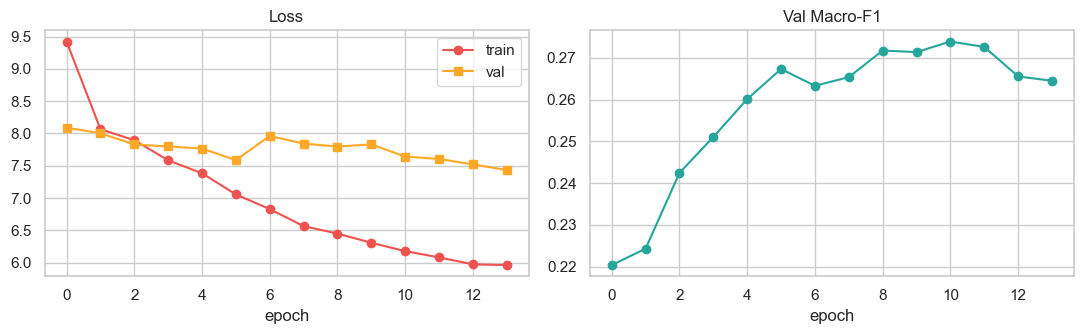

In [45]:
# Plot history
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(history['train_loss'], marker='o', color='#EF5350', label='train')
if history.get('val_loss'):
    ax[0].plot(history['val_loss'], marker='s', color='#FFA726', label='val')
ax[0].set_title('Loss'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(history['val_macro_f1'], marker='o', color='#26A69A')
ax[1].set_title('Val Macro-F1'); ax[1].set_xlabel('epoch')
plt.tight_layout(); plt.show()

## 7. Đánh giá trên Test

In [46]:
test_f1, per_aspect_f1, Yt, Pt = evaluate(model, Xte, Y_te)
print(f'🧪 Test Macro-F1 (mean across aspects): {test_f1:.4f}')

per_asp = pd.DataFrame({'aspect': aspect_cols, 'macro_f1': per_aspect_f1}).set_index('aspect').round(4)
display(per_asp)

from collections import Counter
support = (Y_tr != LABEL2ID[NONE_LABEL]).sum(axis=0)
top_idx = np.argsort(-support)[:3]
for i in top_idx:
    asp = aspect_cols[i]
    print(f"\n━━━ {asp} ━━━")
    y_true = [ID2LABEL[v] for v in Yt[:, i]]
    y_pred = [ID2LABEL[v] for v in Pt[:, i]]
    print(classification_report(y_true, y_pred, zero_division=0))

🧪 Test Macro-F1 (mean across aspects): 0.2776


,macro_f1
aspect,
FOOD#QUALITY,0.2830
FOOD#STYLE&OPTIONS,0.2954
AMBIENCE#GENERAL,0.2657
RESTAURANT#GENERAL,0.2058
SERVICE#GENERAL,0.2575
FOOD#PRICES,0.2505
RESTAURANT#PRICES,0.2373
LOCATION#GENERAL,0.2332
RESTAURANT#MISCELLANEOUS,0.2420



━━━ FOOD#QUALITY ━━━
              precision    recall  f1-score   support

    __NONE__       0.00      0.00      0.00        44
    negative       0.04      0.10      0.06        10
     neutral       0.20      0.38      0.26        42
    positive       0.83      0.80      0.81       340

    accuracy                           0.67       436
   macro avg       0.27      0.32      0.28       436
weighted avg       0.66      0.67      0.66       436


━━━ FOOD#STYLE&OPTIONS ━━━
              precision    recall  f1-score   support

    __NONE__       0.44      0.77      0.56       154
    negative       0.05      0.06      0.05        16
     neutral       0.10      0.26      0.14        19
    positive       0.77      0.30      0.43       247

    accuracy                           0.45       436
   macro avg       0.34      0.35      0.30       436
weighted avg       0.60      0.45      0.45       436


━━━ FOOD#PRICES ━━━
              precision    recall  f1-score   support

    

## 8. So sánh với baseline TF-IDF (Step 2.1)

=== Test Macro-F1: BiLSTM vs TF-IDF ===


,macro_f1,tfidf_f1,delta
aspect,,,
FOOD#QUALITY,0.2830,0.4849,-0.2019
FOOD#STYLE&OPTIONS,0.2954,0.4839,-0.1885
AMBIENCE#GENERAL,0.2657,0.5691,-0.3034
RESTAURANT#GENERAL,0.2058,0.3607,-0.1549
SERVICE#GENERAL,0.2575,0.5035,-0.2460
FOOD#PRICES,0.2505,0.5664,-0.3159
RESTAURANT#PRICES,0.2373,0.3011,-0.0638
LOCATION#GENERAL,0.2332,0.4783,-0.2451
RESTAURANT#MISCELLANEOUS,0.2420,0.3765,-0.1345


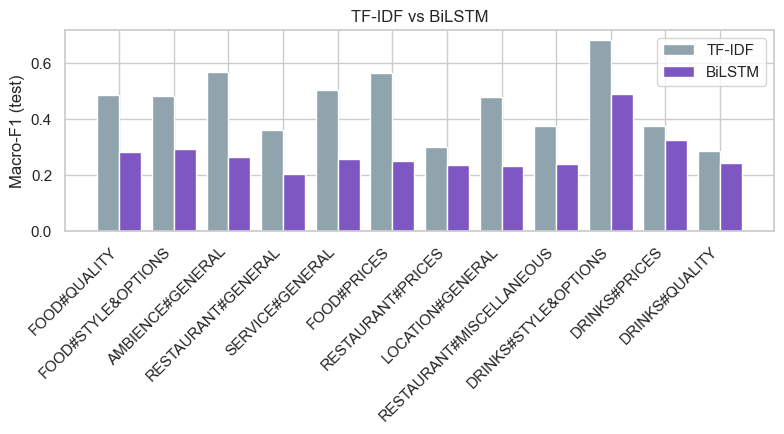

In [47]:
out_dir = pathlib.Path('../outputs/neural_bilstm')
out_dir.mkdir(parents=True, exist_ok=True)

baseline_csv = pathlib.Path('../outputs/baseline/test_metrics.csv')
if baseline_csv.exists():
    base = pd.read_csv(baseline_csv, index_col=0)
    comp = per_asp.join(base[['macro_f1']].rename(columns={'macro_f1': 'tfidf_f1'}), how='left')
    comp['delta'] = (comp['macro_f1'] - comp['tfidf_f1']).round(4)
    print('=== Test Macro-F1: BiLSTM vs TF-IDF ===')
    display(comp)

    # Bar chart
    fig, ax = plt.subplots(figsize=(max(8, 0.45 * len(aspect_cols)), 4.5))
    x = np.arange(len(aspect_cols)); w = 0.4
    ax.bar(x - w/2, comp['tfidf_f1'].fillna(0),  w, label='TF-IDF', color='#90A4AE')
    ax.bar(x + w/2, comp['macro_f1'],            w, label='BiLSTM', color='#7E57C2')
    ax.set_xticks(x); ax.set_xticklabels(aspect_cols, rotation=45, ha='right')
    ax.set_ylabel('Macro-F1 (test)'); ax.set_title('TF-IDF vs BiLSTM')
    ax.legend(); plt.tight_layout()
    plt.savefig(out_dir / 'compare_tfidf_vs_bilstm.png', dpi=120)
    plt.show()
else:
    print('ℹ️  Chưa có outputs/baseline/test_metrics.csv — bỏ qua so sánh.')

## 9. Lưu artifacts

In [48]:
# Save model + vocab + config (Keras)
model.save_weights(str(out_dir / 'bilstm_multihead.weights.h5'))
with open(out_dir / 'vocab.json', 'w', encoding='utf-8') as fh:
    json.dump({'itos': itos, 'pad_id': PAD_ID, 'unk_id': UNK_ID}, fh, ensure_ascii=False)

per_asp.to_csv(out_dir / 'test_metrics.csv')
summary = {
    'framework':     'tensorflow',
    'tf_version':    tf.__version__,
    'vocab_size':    len(itos),
    'emb_dim':       int(emb_matrix.shape[1]),
    'pretrained':    bool(emb_file),
    'n_aspects':     len(aspect_cols),
    'max_len':       MAX_LEN,
    'batch_size':    BATCH_SIZE,
    'val_macro_f1':  float(best_f1),
    'test_macro_f1': float(test_f1),
    'history':       history,
}
with open(out_dir / 'summary.json', 'w', encoding='utf-8') as fh:
    json.dump(summary, fh, ensure_ascii=False, indent=2, default=str)

print(f"✅ Saved to {out_dir.resolve()}")
for p in sorted(out_dir.iterdir()):
    print(f"   • {p.name}")

✅ Saved to C:\Users\annt43\Desktop\finalProject\outputs\neural_bilstm
   • bilstm_multihead.weights.h5
   • compare_tfidf_vs_bilstm.png
   • summary.json
   • test_metrics.csv
   • vocab.json


---
## ✅ Checklist Step 2.2 (Keras)

- [x] Build vocab + encode từ `text_tokenized`
- [x] (Optional) fastText VN embeddings
- [x] Shared BiLSTM + N heads (multi-task) — Keras Functional API
- [x] Class-weighted CrossEntropy (sample_weight theo true class)
- [x] Early-stopping theo Macro-F1 val
- [x] So sánh TF-IDF vs BiLSTM (test)
- [x] Lưu model (`.weights.h5`), vocab, metrics, summary

**Bước tiếp theo:** Step 3 — PhoBERT fine-tuning → `notebooks/05_PhoBERT_Finetune.ipynb`